
# YOLO26 Baseline Error Diagnosis for RDD2022-China

Run this notebook **after** the baseline training has finished.

It does not train another model. It loads the existing `best.pt` checkpoint from Google Drive and answers:

1. Which classes are confused with each other?
2. Which objects are completely missed?
3. Are thin/high-aspect-ratio cracks the dominant problem?
4. Are errors mainly classification, localization, or false positives?
5. Which architecture modification should be tested first?

The output is designed to guide the next custom YOLO26 architecture experiment.


## 1. Install dependencies

In [1]:

!pip -q install -U ultralytics pandas scipy pyyaml pillow


In [2]:

import gc
import json
import math
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont
from ultralytics import YOLO

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Use a T4 GPU runtime."
print("GPU:", torch.cuda.get_device_name(0))

DEVICE = 0
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 2. Mount Drive and configure paths

In [3]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [4]:

# ================= USER CONFIG =================
LOCAL_ROOT = Path("/content/China_Subset")
DRIVE_ZIP = Path("/content/drive/MyDrive/Research/Dataset/China_Subset.zip")

BASELINE_CKPT = Path(
    "/content/drive/MyDrive/Research/runs_rdd2022/"
    "yolo26s_fresh/train/weights/best.pt"
)

OUT_DIR = Path(
    "/content/drive/MyDrive/Research/runs_rdd2022/"
    "yolo26s_baseline_diagnostics"
)

IMGSZ = 640
PRED_CONF = 0.05
MATCH_IOU = 0.50
VAL_BATCH = 8
PRED_BATCH = 4
WORKERS = 2
MAX_ERROR_VISUALS = 40
# ===============================================

CLASS_NAMES = [
    "longitudinal crack",
    "transverse crack",
    "alligator crack",
    "pothole",
    "repair",
]
NUM_CLASSES = len(CLASS_NAMES)

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "visuals").mkdir(parents=True, exist_ok=True)

assert BASELINE_CKPT.exists(), f"Checkpoint not found: {BASELINE_CKPT}"

if not LOCAL_ROOT.exists():
    assert DRIVE_ZIP.exists(), f"Dataset zip not found: {DRIVE_ZIP}"
    shutil.copy2(DRIVE_ZIP, "/content/China_Subset.zip")
    shutil.unpack_archive("/content/China_Subset.zip", "/content")

yaml_path = LOCAL_ROOT / "dataset_diagnostic.yaml"
with open(yaml_path, "w") as f:
    yaml.safe_dump({
        "path": str(LOCAL_ROOT),
        "train": "train_set/images",
        "val": "valid_set/images",
        "test": "test_set/images",
        "nc": NUM_CLASSES,
        "names": CLASS_NAMES,
    }, f, sort_keys=False)

print("Checkpoint:", BASELINE_CKPT)
print("Output:", OUT_DIR)


Checkpoint: /content/drive/MyDrive/Research/runs_rdd2022/yolo26s_fresh/train/weights/best.pt
Output: /content/drive/MyDrive/Research/runs_rdd2022/yolo26s_baseline_diagnostics


## 3. Official baseline metrics

In [5]:

model = YOLO(str(BASELINE_CKPT))

metrics = model.val(
    data=str(yaml_path),
    split="test",
    imgsz=IMGSZ,
    batch=VAL_BATCH,
    device=DEVICE,
    workers=WORKERS,
    verbose=False,
    plots=False,
)

rows = [{
    "class_id": -1,
    "class_name": "ALL",
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
}]

for class_id, name in metrics.names.items():
    rows.append({
        "class_id": int(class_id),
        "class_name": CLASS_NAMES[int(class_id)],
        "mAP50": float(metrics.box.ap50[int(class_id)]),
        "mAP50_95": float(metrics.box.maps[int(class_id)]),
        "precision": np.nan,
        "recall": np.nan,
    })

official_df = pd.DataFrame(rows)
display(official_df.round(4))
official_df.to_csv(OUT_DIR / "official_metrics.csv", index=False)

del metrics
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,467,115 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2107.2±501.8 MB/s, size: 83.9 KB)
val: Scanning /content/China_Subset/test_set/labels... 438 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 438/438 2.4Kit/s 0.2s
val: New cache created: /content/China_Subset/test_set/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 8.0it/s 6.9s
                   all        438        893      0.856      0.799      0.845       0.58
Speed: 0.9ms preprocess, 9.1ms inference, 0.0ms loss, 0.1ms postprocess per image


,class_id,class_name,mAP50,mAP50_95,precision,recall
0,-1,ALL,0.8453,0.5802,0.8563,0.7992
1,0,longitudinal crack,0.8180,0.5414,NaN,NaN
2,1,transverse crack,0.8605,0.5560,NaN,NaN
3,2,alligator crack,0.8099,0.5220,NaN,NaN
4,3,pothole,0.9061,0.5645,NaN,NaN
5,4,repair,0.8318,0.7172,NaN,NaN


## 4. Load test ground truth

In [6]:

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_image(image_dir: Path, stem: str):
    matches = [p for p in image_dir.glob(f"{stem}.*") if p.suffix.lower() in IMAGE_SUFFIXES]
    return matches[0] if matches else None

def load_ground_truth(split="test_set"):
    image_dir = LOCAL_ROOT / split / "images"
    label_dir = LOCAL_ROOT / split / "labels"
    rows = []

    for label_path in sorted(label_dir.glob("*.txt")):
        image_path = find_image(image_dir, label_path.stem)
        if image_path is None:
            continue

        with Image.open(image_path) as image:
            width, height = image.size

        text = label_path.read_text().strip()
        if not text:
            continue

        for object_index, line in enumerate(text.splitlines()):
            fields = line.split()
            if len(fields) < 5:
                continue

            class_id = int(float(fields[0]))
            xc, yc, bw, bh = map(float, fields[1:5])

            box_w = bw * width
            box_h = bh * height
            x1 = xc * width - box_w / 2
            y1 = yc * height - box_h / 2
            x2 = x1 + box_w
            y2 = y1 + box_h

            area_ratio = (box_w * box_h) / max(width * height, 1)
            aspect_ratio = max(box_w, box_h) / max(min(box_w, box_h), 1e-9)

            rows.append({
                "stem": image_path.stem,
                "image_path": str(image_path),
                "object_index": object_index,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "width": box_w,
                "height": box_h,
                "area_ratio": area_ratio,
                "aspect_ratio": aspect_ratio,
            })

    return pd.DataFrame(rows)

gt_df = load_ground_truth()

gt_df["aspect_bucket"] = pd.cut(
    gt_df.aspect_ratio,
    bins=[0, 2, 4, 8, np.inf],
    labels=["AR<2", "AR2-4", "AR4-8", "AR>=8"],
)

gt_df["area_bucket"] = pd.cut(
    gt_df.area_ratio,
    bins=[0, 0.001, 0.005, 0.02, np.inf],
    labels=["tiny", "small", "medium", "large"],
)

print("GT objects:", len(gt_df))
display(gt_df.class_name.value_counts().reindex(CLASS_NAMES).fillna(0).astype(int))


GT objects: 893


class_name
longitudinal crack    437
transverse crack      241
alligator crack        87
pothole                30
repair                 98
Name: count, dtype: int64

## 5. Generate and cache predictions

In [7]:

prediction_csv = OUT_DIR / f"test_predictions_conf_{PRED_CONF:.2f}.csv"

if prediction_csv.exists():
    pred_df = pd.read_csv(prediction_csv)
    print("Loaded cached predictions:", prediction_csv)
else:
    image_paths = sorted([
        p for p in (LOCAL_ROOT / "test_set" / "images").iterdir()
        if p.suffix.lower() in IMAGE_SUFFIXES
    ])

    pred_rows = []
    for start in range(0, len(image_paths), 32):
        batch_paths = image_paths[start:start + 32]
        results = model.predict(
            [str(p) for p in batch_paths],
            imgsz=IMGSZ,
            conf=PRED_CONF,
            batch=PRED_BATCH,
            device=DEVICE,
            verbose=False,
            stream=True,
        )

        for image_path, result in zip(batch_paths, results):
            boxes = result.boxes
            if boxes is None or len(boxes) == 0:
                continue

            xyxy = boxes.xyxy.detach().cpu().numpy()
            cls = boxes.cls.detach().cpu().numpy().astype(int)
            conf = boxes.conf.detach().cpu().numpy()

            for i in range(len(xyxy)):
                pred_rows.append({
                    "stem": image_path.stem,
                    "image_path": str(image_path),
                    "prediction_index": i,
                    "pred_class_id": int(cls[i]),
                    "pred_class_name": CLASS_NAMES[int(cls[i])],
                    "confidence": float(conf[i]),
                    "x1": float(xyxy[i, 0]),
                    "y1": float(xyxy[i, 1]),
                    "x2": float(xyxy[i, 2]),
                    "y2": float(xyxy[i, 3]),
                })

    pred_df = pd.DataFrame(pred_rows)
    pred_df.to_csv(prediction_csv, index=False)
    print("Saved predictions:", prediction_csv)

print("Predicted boxes:", len(pred_df))
display(pred_df.head())


Saved predictions: /content/drive/MyDrive/Research/runs_rdd2022/yolo26s_baseline_diagnostics/test_predictions_conf_0.05.csv
Predicted boxes: 1505


,stem,image_path,prediction_index,pred_class_id,pred_class_name,confidence,x1,y1,x2,y2
0,China_Drone_000004,/content/China_Subset/test_set/images/China_Dr...,0,2,alligator crack,0.917744,3.115491,192.668854,307.151428,325.034149
1,China_Drone_000014,/content/China_Subset/test_set/images/China_Dr...,0,1,transverse crack,0.724330,155.861237,175.635971,353.728241,210.722336
2,China_Drone_000014,/content/China_Subset/test_set/images/China_Dr...,1,1,transverse crack,0.106291,156.518539,176.993713,348.462128,211.011551
3,China_Drone_000017,/content/China_Subset/test_set/images/China_Dr...,0,1,transverse crack,0.806698,47.942158,354.560272,198.159576,375.201080
4,China_Drone_000026,/content/China_Subset/test_set/images/China_Dr...,0,0,longitudinal crack,0.865234,113.746132,0.652124,145.245361,117.573730


## 6. Match predictions to ground truth

In [8]:

def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)

    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])

    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)

    area_a = (
        np.clip(a[:, 2] - a[:, 0], 0, None)
        * np.clip(a[:, 3] - a[:, 1], 0, None)
    )
    area_b = (
        np.clip(b[:, 2] - b[:, 0], 0, None)
        * np.clip(b[:, 3] - b[:, 1], 0, None)
    )

    union = area_a[:, None] + area_b[None, :] - inter
    return inter / np.clip(union, 1e-9, None)

match_rows = []
unmatched_gt_rows = []
unmatched_pred_rows = []

all_stems = sorted(set(gt_df.stem) | set(pred_df.stem))

for stem in all_stems:
    gt_part = gt_df[gt_df.stem == stem].reset_index(drop=False)
    pred_part = pred_df[pred_df.stem == stem].reset_index(drop=False)

    gt_boxes = gt_part[["x1", "y1", "x2", "y2"]].to_numpy(float) if len(gt_part) else np.zeros((0, 4))
    pred_boxes = pred_part[["x1", "y1", "x2", "y2"]].to_numpy(float) if len(pred_part) else np.zeros((0, 4))

    ious = iou_matrix(gt_boxes, pred_boxes)

    candidates = []
    for gi in range(len(gt_part)):
        for pi in range(len(pred_part)):
            if ious[gi, pi] >= MATCH_IOU:
                # Sort primarily by IoU, secondarily by confidence.
                candidates.append((
                    float(ious[gi, pi]),
                    float(pred_part.iloc[pi].confidence),
                    gi,
                    pi,
                ))

    candidates.sort(reverse=True)
    used_gt, used_pred = set(), set()

    for iou_value, confidence, gi, pi in candidates:
        if gi in used_gt or pi in used_pred:
            continue

        used_gt.add(gi)
        used_pred.add(pi)

        g = gt_part.iloc[gi]
        p = pred_part.iloc[pi]

        match_rows.append({
            "stem": stem,
            "image_path": g.image_path,
            "gt_index": int(g["index"]),
            "pred_index": int(p["index"]),
            "true_class_id": int(g.class_id),
            "true_class_name": g.class_name,
            "pred_class_id": int(p.pred_class_id),
            "pred_class_name": p.pred_class_name,
            "confidence": float(p.confidence),
            "iou": iou_value,
            "class_correct": int(g.class_id) == int(p.pred_class_id),
            "aspect_ratio": float(g.aspect_ratio),
            "aspect_bucket": str(g.aspect_bucket),
            "area_ratio": float(g.area_ratio),
            "area_bucket": str(g.area_bucket),
            "gt_x1": float(g.x1),
            "gt_y1": float(g.y1),
            "gt_x2": float(g.x2),
            "gt_y2": float(g.y2),
            "pred_x1": float(p.x1),
            "pred_y1": float(p.y1),
            "pred_x2": float(p.x2),
            "pred_y2": float(p.y2),
        })

    for gi in range(len(gt_part)):
        if gi not in used_gt:
            g = gt_part.iloc[gi]
            unmatched_gt_rows.append({
                "stem": stem,
                "image_path": g.image_path,
                "gt_index": int(g["index"]),
                "true_class_id": int(g.class_id),
                "true_class_name": g.class_name,
                "aspect_ratio": float(g.aspect_ratio),
                "aspect_bucket": str(g.aspect_bucket),
                "area_ratio": float(g.area_ratio),
                "area_bucket": str(g.area_bucket),
                "gt_x1": float(g.x1),
                "gt_y1": float(g.y1),
                "gt_x2": float(g.x2),
                "gt_y2": float(g.y2),
            })

    for pi in range(len(pred_part)):
        if pi not in used_pred:
            p = pred_part.iloc[pi]
            unmatched_pred_rows.append({
                "stem": stem,
                "image_path": p.image_path,
                "pred_index": int(p["index"]),
                "pred_class_id": int(p.pred_class_id),
                "pred_class_name": p.pred_class_name,
                "confidence": float(p.confidence),
                "pred_x1": float(p.x1),
                "pred_y1": float(p.y1),
                "pred_x2": float(p.x2),
                "pred_y2": float(p.y2),
            })

matched_df = pd.DataFrame(match_rows)
missed_df = pd.DataFrame(unmatched_gt_rows)
false_positive_df = pd.DataFrame(unmatched_pred_rows)

matched_df.to_csv(OUT_DIR / "matched_predictions.csv", index=False)
missed_df.to_csv(OUT_DIR / "missed_ground_truth.csv", index=False)
false_positive_df.to_csv(OUT_DIR / "false_positive_predictions.csv", index=False)

print("Matched GT-pred pairs:", len(matched_df))
print("Missed GT objects:", len(missed_df))
print("Unmatched predictions:", len(false_positive_df))


Matched GT-pred pairs: 777
Missed GT objects: 116
Unmatched predictions: 728


## 7. Classification confusion among localized objects

predicted,longitudinal crack,transverse crack,alligator crack,pothole,repair
true,,,,,
longitudinal crack,375,1,1,0,0
transverse crack,3,208,0,0,0
alligator crack,0,0,74,0,0
pothole,0,0,1,28,0
repair,2,0,0,0,84


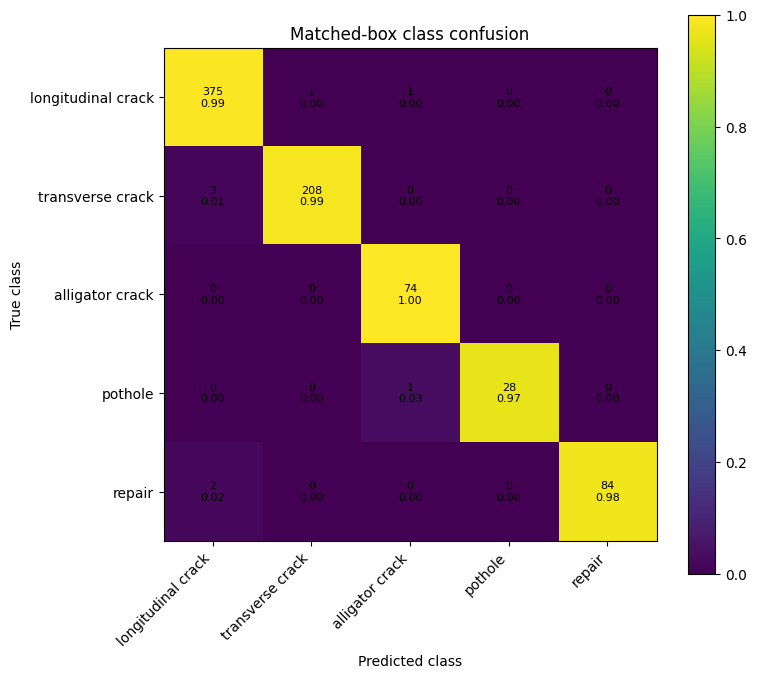

In [9]:

confusion = pd.crosstab(
    pd.Categorical(
        matched_df.true_class_name,
        categories=CLASS_NAMES,
    ),
    pd.Categorical(
        matched_df.pred_class_name,
        categories=CLASS_NAMES,
    ),
    dropna=False,
)

confusion.index.name = "true"
confusion.columns.name = "predicted"

display(confusion)
confusion.to_csv(OUT_DIR / "matched_class_confusion_matrix.csv")

row_normalized = confusion.div(confusion.sum(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(row_normalized.fillna(0).to_numpy(), vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Matched-box class confusion")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        count = int(confusion.iloc[i, j])
        fraction = row_normalized.iloc[i, j]
        fraction = 0 if pd.isna(fraction) else fraction
        ax.text(j, i, f"{count}\n{fraction:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "matched_class_confusion_matrix.png", dpi=200)
plt.show()


In [10]:

confusion_pairs = []

for true_id, true_name in enumerate(CLASS_NAMES):
    true_rows = matched_df[matched_df.true_class_id == true_id]
    denominator = max(len(true_rows), 1)

    for pred_id, pred_name in enumerate(CLASS_NAMES):
        if true_id == pred_id:
            continue

        count = len(
            true_rows[true_rows.pred_class_id == pred_id]
        )

        if count > 0:
            confusion_pairs.append({
                "true_class": true_name,
                "predicted_as": pred_name,
                "count": count,
                "fraction_of_localized_true_class": count / denominator,
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs)
if len(confusion_pairs_df):
    confusion_pairs_df = confusion_pairs_df.sort_values(
        ["fraction_of_localized_true_class", "count"],
        ascending=False,
    )

display(confusion_pairs_df.head(20).round(4))
confusion_pairs_df.to_csv(OUT_DIR / "top_confusion_pairs.csv", index=False)


,true_class,predicted_as,count,fraction_of_localized_true_class
3,pothole,alligator crack,1,0.0345
4,repair,longitudinal crack,2,0.0233
2,transverse crack,longitudinal crack,3,0.0142
0,longitudinal crack,transverse crack,1,0.0027
1,longitudinal crack,alligator crack,1,0.0027


## 8. Per-class error decomposition

In [11]:

decomposition_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):
    gt_count = int((gt_df.class_id == class_id).sum())
    localized = matched_df[matched_df.true_class_id == class_id]
    correct = int(localized.class_correct.sum())
    wrong_class = int((~localized.class_correct).sum())
    missed = int((missed_df.true_class_id == class_id).sum())
    fp = int((false_positive_df.pred_class_id == class_id).sum())

    decomposition_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "gt_objects": gt_count,
        "correctly_detected_and_classified": correct,
        "localized_but_wrong_class": wrong_class,
        "missed_objects": missed,
        "false_positive_predictions": fp,
        "correct_recall": correct / max(gt_count, 1),
        "localization_recall_any_class": len(localized) / max(gt_count, 1),
        "classification_accuracy_given_localized": correct / max(len(localized), 1),
        "mean_iou_for_matched": localized.iou.mean() if len(localized) else np.nan,
    })

decomposition_df = pd.DataFrame(decomposition_rows)
display(decomposition_df.round(4))
decomposition_df.to_csv(OUT_DIR / "per_class_error_decomposition.csv", index=False)


,class_id,class_name,gt_objects,correctly_detected_and_classified,localized_but_wrong_class,missed_objects,false_positive_predictions,correct_recall,localization_recall_any_class,classification_accuracy_given_localized,mean_iou_for_matched
0,0,longitudinal crack,437,375,2,60,402,0.8581,0.8627,0.9947,0.8111
1,1,transverse crack,241,208,3,30,216,0.8631,0.8755,0.9858,0.8095
2,2,alligator crack,87,74,0,13,53,0.8506,0.8506,1.0000,0.8180
3,3,pothole,30,28,1,1,14,0.9333,0.9667,0.9655,0.8062
4,4,repair,98,84,2,12,43,0.8571,0.8776,0.9767,0.9006


## 9. Miss rate by aspect ratio and object size

In [12]:

gt_status = gt_df.copy()
gt_status["matched"] = False
gt_status["correct_class"] = False

if len(matched_df):
    gt_status.loc[matched_df.gt_index.to_numpy(), "matched"] = True
    correct_gt_indices = matched_df.loc[
        matched_df.class_correct,
        "gt_index",
    ].to_numpy()
    gt_status.loc[correct_gt_indices, "correct_class"] = True

def grouped_status(group_column):
    rows = []
    for group_value, part in gt_status.groupby(group_column, observed=True):
        rows.append({
            group_column: str(group_value),
            "n_gt": len(part),
            "localization_recall": part.matched.mean(),
            "correct_detection_recall": part.correct_class.mean(),
            "miss_rate": 1.0 - part.matched.mean(),
            "localized_wrong_class_rate": (
                (part.matched & ~part.correct_class).mean()
            ),
        })
    return pd.DataFrame(rows)

aspect_df = grouped_status("aspect_bucket")
area_df = grouped_status("area_bucket")

print("Aspect-ratio analysis")
display(aspect_df.round(4))

print("Area analysis")
display(area_df.round(4))

aspect_df.to_csv(OUT_DIR / "error_by_aspect_ratio.csv", index=False)
area_df.to_csv(OUT_DIR / "error_by_area.csv", index=False)


Aspect-ratio analysis


,aspect_bucket,n_gt,localization_recall,correct_detection_recall,miss_rate,localized_wrong_class_rate
0,AR<2,235,0.8340,0.8298,0.1660,0.0043
1,AR2-4,252,0.8810,0.8571,0.1190,0.0238
2,AR4-8,293,0.8805,0.8771,0.1195,0.0034
3,AR>=8,113,0.8938,0.8938,0.1062,0.0000


Area analysis


,area_bucket,n_gt,localization_recall,correct_detection_recall,miss_rate,localized_wrong_class_rate
0,tiny,6,0.8333,0.8333,0.1667,0.0000
1,small,51,0.8824,0.8824,0.1176,0.0000
2,medium,265,0.8377,0.8226,0.1623,0.0151
3,large,571,0.8844,0.8774,0.1156,0.0070


## 10. Background false positives

In [13]:

fp_summary = (
    false_positive_df.groupby("pred_class_name")
    .agg(
        false_positives=("pred_class_name", "size"),
        mean_confidence=("confidence", "mean"),
        median_confidence=("confidence", "median"),
    )
    .reindex(CLASS_NAMES)
    .fillna(0)
    .reset_index()
)

display(fp_summary.round(4))
fp_summary.to_csv(OUT_DIR / "false_positive_summary.csv", index=False)


,pred_class_name,false_positives,mean_confidence,median_confidence
0,longitudinal crack,402,0.2801,0.1606
1,transverse crack,216,0.2855,0.1595
2,alligator crack,53,0.3257,0.1998
3,pothole,14,0.2362,0.1247
4,repair,43,0.3106,0.1578


## 11. Save example error images

In [14]:

def draw_box(draw, box, text, width=3):
    x1, y1, x2, y2 = map(float, box)
    draw.rectangle([x1, y1, x2, y2], outline="white", width=width)
    draw.text((x1 + 2, max(0, y1 - 14)), text, fill="white")

def save_misclassification_visuals(dataframe, limit):
    if len(dataframe) == 0:
        return

    sample = dataframe.sort_values(
        ["class_correct", "confidence"],
        ascending=[True, False],
    )
    sample = sample[~sample.class_correct].head(limit)

    for index, row in sample.iterrows():
        with Image.open(row.image_path) as image:
            image = image.convert("RGB")
            draw = ImageDraw.Draw(image)

            draw_box(
                draw,
                [row.gt_x1, row.gt_y1, row.gt_x2, row.gt_y2],
                f"GT: {row.true_class_name}",
                width=4,
            )
            draw_box(
                draw,
                [row.pred_x1, row.pred_y1, row.pred_x2, row.pred_y2],
                f"PRED: {row.pred_class_name} {row.confidence:.2f}",
                width=2,
            )

            filename = (
                f"miscls_{index:04d}_"
                f"{row.true_class_id}_to_{row.pred_class_id}.jpg"
            )
            image.save(OUT_DIR / "visuals" / filename, quality=92)

def save_missed_visuals(dataframe, limit):
    if len(dataframe) == 0:
        return

    sample = dataframe.sort_values(
        ["aspect_ratio", "area_ratio"],
        ascending=[False, True],
    ).head(limit)

    for index, row in sample.iterrows():
        with Image.open(row.image_path) as image:
            image = image.convert("RGB")
            draw = ImageDraw.Draw(image)
            draw_box(
                draw,
                [row.gt_x1, row.gt_y1, row.gt_x2, row.gt_y2],
                f"MISSED: {row.true_class_name}",
                width=4,
            )
            filename = (
                f"missed_{index:04d}_class_{row.true_class_id}_"
                f"ar_{row.aspect_ratio:.1f}.jpg"
            )
            image.save(OUT_DIR / "visuals" / filename, quality=92)

save_misclassification_visuals(matched_df, MAX_ERROR_VISUALS)
save_missed_visuals(missed_df, MAX_ERROR_VISUALS)

print("Saved error examples to:", OUT_DIR / "visuals")


Saved error examples to: /content/drive/MyDrive/Research/runs_rdd2022/yolo26s_baseline_diagnostics/visuals


## 12. Automatic architecture recommendation

In [15]:

overall_gt = len(gt_df)
overall_localized = len(matched_df)
overall_correct = int(matched_df.class_correct.sum())

localization_recall = overall_localized / max(overall_gt, 1)
correct_recall = overall_correct / max(overall_gt, 1)
classification_accuracy_localized = (
    overall_correct / max(overall_localized, 1)
)

wrong_class_rate = (
    (~matched_df.class_correct).sum() / max(overall_localized, 1)
)

high_ar = gt_status[gt_status.aspect_ratio >= 4]
high_ar_miss_rate = (
    1 - high_ar.matched.mean()
    if len(high_ar)
    else np.nan
)

small_objects = gt_status[gt_status.area_ratio < 0.005]
small_miss_rate = (
    1 - small_objects.matched.mean()
    if len(small_objects)
    else np.nan
)

summary = {
    "overall_gt": overall_gt,
    "localization_recall_any_class": localization_recall,
    "correct_detection_recall": correct_recall,
    "classification_accuracy_given_localized": classification_accuracy_localized,
    "wrong_class_rate_given_localized": wrong_class_rate,
    "high_aspect_ratio_miss_rate": high_ar_miss_rate,
    "small_object_miss_rate": small_miss_rate,
}

summary_df = pd.DataFrame([summary])
display(summary_df.round(4))
summary_df.to_csv(OUT_DIR / "diagnostic_summary.csv", index=False)

print("\n=== RECOMMENDED NEXT EXPERIMENT ===")

recommendations = []

if wrong_class_rate >= 0.15:
    recommendations.append(
        "Semantic prototype classification head + confusion-aware margin loss"
    )

if not np.isnan(high_ar_miss_rate) and high_ar_miss_rate >= 0.30:
    recommendations.append(
        "Directional detail adapter and/or lightweight P2-to-P3 high-resolution fusion"
    )

if not np.isnan(small_miss_rate) and small_miss_rate >= 0.30:
    recommendations.append(
        "High-resolution feature preservation or small-object-aware assignment"
    )

mean_iou = matched_df.iou.mean() if len(matched_df) else 0
if mean_iou < 0.65:
    recommendations.append(
        "Localization-focused modification for elongated/irregular boxes"
    )

if len(false_positive_df) > 0.5 * max(overall_gt, 1):
    recommendations.append(
        "Hard-negative mining or background-aware classification regularization"
    )

if not recommendations:
    recommendations.append(
        "Baseline is already balanced; focus on lightweight efficiency gains and multi-domain robustness"
    )

for i, item in enumerate(recommendations, 1):
    print(f"{i}. {item}")


,overall_gt,localization_recall_any_class,correct_detection_recall,classification_accuracy_given_localized,wrong_class_rate_given_localized,high_aspect_ratio_miss_rate,small_object_miss_rate
0,893,0.8701,0.8611,0.9897,0.0103,0.1155,0.1228



=== RECOMMENDED NEXT EXPERIMENT ===
1. Hard-negative mining or background-aware classification regularization



## 13. Upload these results for the next architecture notebook

The most important files are:

```text
diagnostic_summary.csv
per_class_error_decomposition.csv
top_confusion_pairs.csv
error_by_aspect_ratio.csv
error_by_area.csv
false_positive_summary.csv
matched_class_confusion_matrix.csv
official_metrics.csv
```

After these are available, the next notebook should train:

```text
baseline YOLO26s
vs
custom modified YOLO26s
```

The exact modification should be selected from the measured dominant failure rather than chosen in advance.
